10. Business Insights and Visualization

We will cover:
1. Borrower segment insights.
2. Cluster comparisons.
3. Default patterns across borrower segments.
4. Actionable business recommendations.
5. Interactive dashboard using Streamlit.
We will continue one step at a time: I'll provide one code cell, you run it and share the output, and then we'll proceed.

Step 1 – Prepare the business insights notebook.

In [1]:
import pandas as pd
import numpy as np

# Load your credit dataset
df = pd.read_csv(r"D:\HCL_PROJECTS\Credit Portfolio Segmentation and Risk Pattern Analysis Project-3\step2_outputs\cleaned_credit_portfolio.csv"
)

# Check dataset
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# Check required columns
required_columns = [
    'revenue',
    'loan_amnt',
    'fico_n',
    'dti_capped',
    'revenue_log',
    'emp_length',
    'purpose',
    'home_ownership_n',
    'Default'
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

print("\nMissing required columns:", missing_columns)

# Create loan amount log if not already present
if 'loan_amnt_log' not in df.columns:
    df['loan_amnt_log'] = np.log1p(df['loan_amnt'])

print("\nMissing values in required columns:")
print(df[required_columns + ['loan_amnt_log']].isnull().sum())

Dataset shape: (1347681, 15)

Columns:
['id', 'issue_d', 'revenue', 'dti_n', 'loan_amnt', 'fico_n', 'experience_c', 'emp_length', 'purpose', 'home_ownership_n', 'addr_state', 'Default', 'revenue_log', 'dti_capped', 'dti_extreme']

Missing required columns: []

Missing values in required columns:
revenue             0
loan_amnt           0
fico_n              0
dti_capped          0
revenue_log         0
emp_length          0
purpose             0
home_ownership_n    0
Default             0
loan_amnt_log       0
dtype: int64


Step 2 – Overall portfolio performance
First, calculate the overall credit portfolio indicators to establish a baseline for business insights.

In [2]:
# Overall portfolio performance

total_borrowers = len(df)

total_defaults = df['Default'].sum()

default_rate = df['Default'].mean() * 100

average_loan = df['loan_amnt'].mean()

average_revenue = df['revenue'].mean()

average_fico = df['fico_n'].mean()

average_dti = df['dti_capped'].mean()

portfolio_summary = pd.DataFrame({
    'Metric': [
        'Total Borrowers',
        'Total Defaults',
        'Non-Default Borrowers',
        'Overall Default Rate (%)',
        'Average Loan Amount',
        'Average Revenue',
        'Average FICO Score',
        'Average DTI'
    ],
    'Value': [
        total_borrowers,
        total_defaults,
        total_borrowers - total_defaults,
        round(default_rate, 2),
        round(average_loan, 2),
        round(average_revenue, 2),
        round(average_fico, 2),
        round(average_dti, 2)
    ]
})

print("OVERALL CREDIT PORTFOLIO PERFORMANCE")
print(portfolio_summary)

OVERALL CREDIT PORTFOLIO PERFORMANCE
                     Metric       Value
0           Total Borrowers  1347681.00
1            Total Defaults   269249.00
2     Non-Default Borrowers  1078432.00
3  Overall Default Rate (%)       19.98
4       Average Loan Amount    14408.23
5           Average Revenue    77369.68
6        Average FICO Score      698.16
7               Average DTI       18.21


Interpretation – Overall credit portfolio
Your portfolio contains 1.35 million borrowers, with an overall default rate of 19.98%.

Key business observations:
1. Default exposure: 269,249 borrowers defaulted, representing almost one-fifth of the portfolio.
2. Average loan amount: $14,408.
3. Average borrower revenue: $77,370.
4. Average FICO score: 698.16.
5. Average DTI: 18.21.
These figures establish the baseline against which we can compare borrower segments.

Step 3 – Default distribution by loan purpose
Identify which loan purposes contribute most to defaults and which have higher default rates.

In [3]:
# Default analysis by loan purpose

purpose_analysis = df.groupby('purpose').agg(
    Total_Borrowers=('Default', 'count'),
    Default_Count=('Default', 'sum'),
    Average_Loan_Amount=('loan_amnt', 'mean'),
    Average_FICO=('fico_n', 'mean'),
    Average_DTI=('dti_capped', 'mean')
)

purpose_analysis['Default_Rate'] = (
    purpose_analysis['Default_Count'] /
    purpose_analysis['Total_Borrowers'] * 100
)

purpose_analysis = purpose_analysis.sort_values(
    'Default_Rate', ascending=False
).round(2)

print("DEFAULT DISTRIBUTION BY LOAN PURPOSE")
print(purpose_analysis)

DEFAULT DISTRIBUTION BY LOAN PURPOSE
                    Total_Borrowers  Default_Count  Average_Loan_Amount  \
purpose                                                                   
small_business                15575           4650             15631.85   
renewable_energy                936            222             10004.33   
moving                         9520           2229              7852.97   
house                          7294           1598             15354.47   
medical                       15606           3409              8990.00   
debt_consolidation           781206         165258             15224.05   
other                         78263          16501              9812.18   
educational                     423             88              6616.08   
vacation                       9083           1743              6189.07   
major_purchase                29543           5496             11817.52   
home_improvement              87684          15570             

Interpretation – Default distribution by loan purpose
Your results reveal significant differences in default rates across loan purposes.

1. Highest default rates
Loan purpose	Default rate
Small business	29.86%
Renewable energy	23.72%
Moving	23.41%
House	21.91%
Medical	21.84%

2. Lowest default rates
Loan purpose	Default rate
Wedding	12.43%
Car	14.70%
Credit card	16.93%
Home improvement	17.76%

3. Important business observations
- Small business loans: Highest default rate at 29.86%, making this segment worth investigating.
- Debt consolidation: Largest portfolio segment, with 781,206 borrowers and 165,258 defaults. Its default rate is 21.15%.
- Credit card loans: Second-largest segment, with 295,551 borrowers, but a relatively lower default rate of 16.93%.
- Wedding loans: Lowest default rate at 12.43%.
Remember: a high default rate and a high number of defaults are different measures. Small business has the highest rate, whereas debt consolidation contributes the largest number of defaults.

Step 4 – Visualize default rates by loan purpose

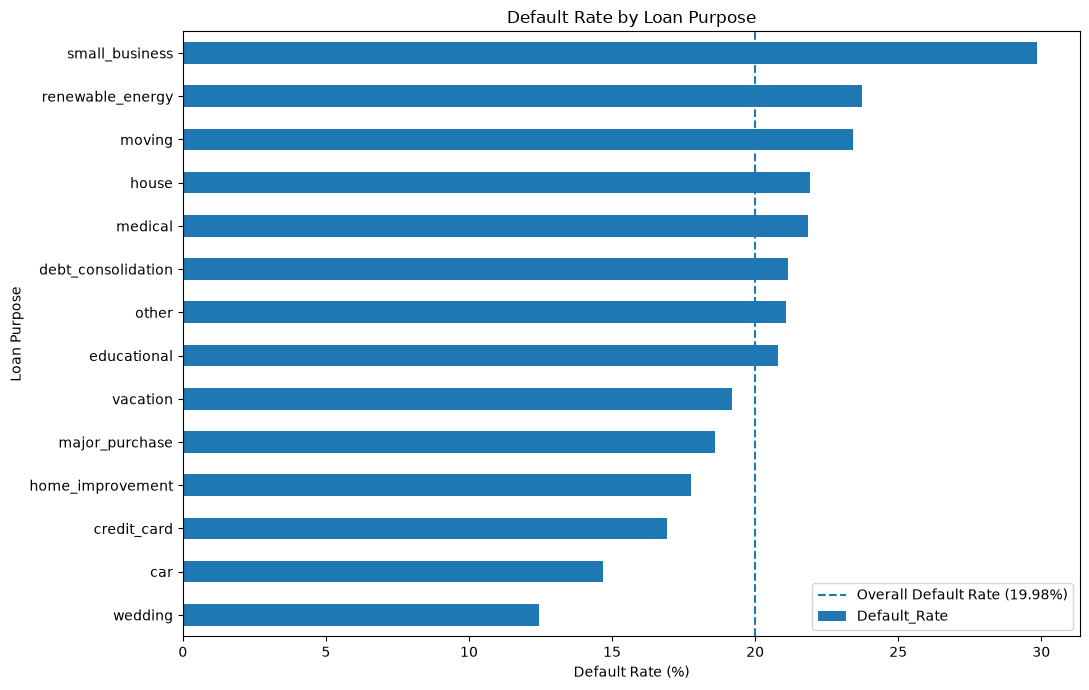

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 7))

purpose_analysis['Default_Rate'].sort_values().plot(
    kind='barh'
)

plt.axvline(
    x=default_rate,
    linestyle='--',
    label=f'Overall Default Rate ({default_rate:.2f}%)'
)

plt.title('Default Rate by Loan Purpose')
plt.xlabel('Default Rate (%)')
plt.ylabel('Loan Purpose')
plt.legend()
plt.tight_layout()
plt.show()

Step 5 – Default distribution by employment length

In [5]:
employment_analysis = df.groupby('emp_length').agg(
    Total_Borrowers=('Default', 'count'),
    Default_Count=('Default', 'sum'),
    Average_Loan_Amount=('loan_amnt', 'mean'),
    Average_Revenue=('revenue', 'mean'),
    Average_FICO=('fico_n', 'mean')
)

employment_analysis['Default_Rate'] = (
    employment_analysis['Default_Count'] /
    employment_analysis['Total_Borrowers'] * 100
)

employment_analysis = employment_analysis.sort_values(
    'Default_Rate', ascending=False
).round(2)

print("DEFAULT DISTRIBUTION BY EMPLOYMENT LENGTH")
print(employment_analysis)

DEFAULT DISTRIBUTION BY EMPLOYMENT LENGTH
            Total_Borrowers  Default_Count  Average_Loan_Amount  \
emp_length                                                        
NI                    78188          21077             11467.58   
1 year                88841          18289             13451.58   
< 1 year             108517          22289             13769.94   
3 years              107862          21558             13861.99   
8 years               60808          12132             14714.82   
9 years               51019          10158             14826.13   
2 years              122091          24197             13745.45   
4 years               80761          15956             14003.75   
5 years               84326          16545             14144.52   
7 years               59724          11652             14539.71   
6 years               62877          12183             14324.48   
10+ years            442667          83213             15619.91   

            Average

Interpretation – Default distribution by employment length
Your results show that employment length is associated with differences in borrower default rates.

1. Highest default rates
Employment length	Default rate
NI (Not informed)	26.96%
1 year	20.59%
Less than 1 year	20.54%
3 years	19.99%

2. Lowest default rates
Employment length	Default rate
10+ years	18.80%
6 years	19.38%
7 years	19.51%
5 years	19.62%

3. Business observations
- Borrowers with employment length marked NI have the highest default rate (26.96%).
- Borrowers with 10+ years of employment have the lowest default rate (18.80%).
- Average revenue increases from $52,240 for NI borrowers to $84,990 for borrowers with 10+ years of employment.
- FICO scores are relatively similar across employment groups.
Business implication: Employment stability and availability of employment information may be useful considerations in credit risk assessment. However, NI does not necessarily mean unemployed; it means employment length was not informed.

Step 6 – Visualize default rates by employment length

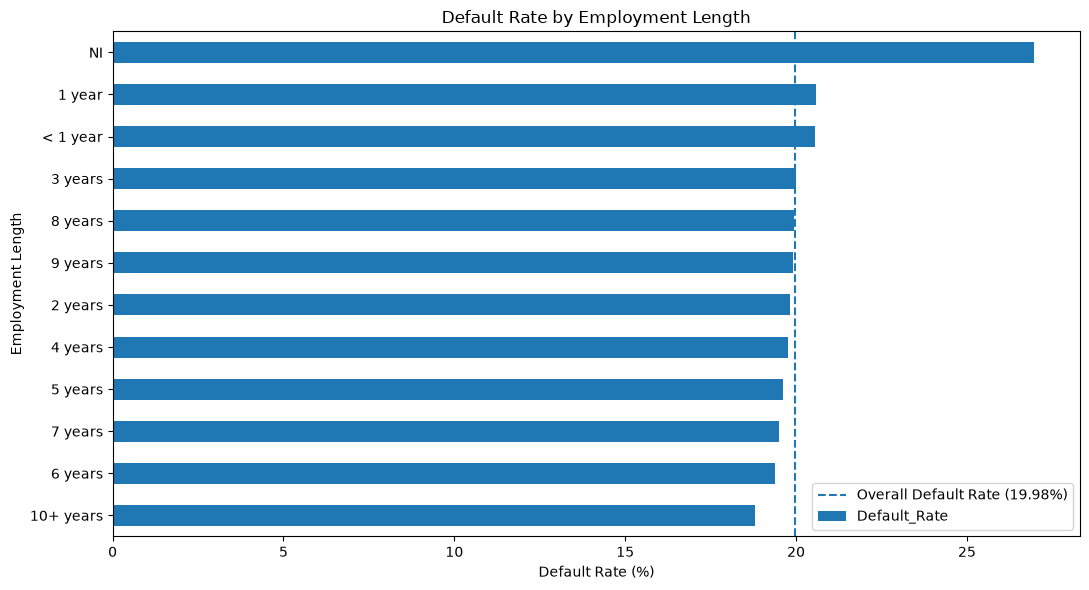

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

employment_analysis['Default_Rate'].sort_values().plot(
    kind='barh'
)

plt.axvline(
    x=default_rate,
    linestyle='--',
    label=f'Overall Default Rate ({default_rate:.2f}%)'
)

plt.title('Default Rate by Employment Length')
plt.xlabel('Default Rate (%)')
plt.ylabel('Employment Length')
plt.legend()
plt.tight_layout()
plt.show()

Step 7 – Default distribution by home ownership
Let's investigate whether home ownership categories are associated with different default rates.

In [7]:
home_analysis = df.groupby('home_ownership_n').agg(
    Total_Borrowers=('Default', 'count'),
    Default_Count=('Default', 'sum'),
    Average_Loan_Amount=('loan_amnt', 'mean'),
    Average_Revenue=('revenue', 'mean'),
    Average_FICO=('fico_n', 'mean'),
    Average_DTI=('dti_capped', 'mean')
)

home_analysis['Default_Rate'] = (
    home_analysis['Default_Count'] /
    home_analysis['Total_Borrowers'] * 100
)

home_analysis = home_analysis.sort_values(
    'Default_Rate', ascending=False
).round(2)

print("DEFAULT DISTRIBUTION BY HOME OWNERSHIP")
print(home_analysis)

DEFAULT DISTRIBUTION BY HOME OWNERSHIP
                  Total_Borrowers  Default_Count  Average_Loan_Amount  \
home_ownership_n                                                        
RENT                       535585         124408             12625.48   
OWN                        144985          29904             13842.36   
OTHER                         517            102             12788.06   
MORTGAGE                   666594         114835             15964.94   

                  Average_Revenue  Average_FICO  Average_DTI  Default_Rate  
home_ownership_n                                                            
RENT                     65716.88        693.74        18.00         23.23  
OWN                      72165.53        700.08        18.69         20.63  
OTHER                    73376.56        702.96        17.25         19.73  
MORTGAGE                 87867.31        701.29        18.28         17.23  


Interpretation – Default distribution by home ownership
Your results show a clear difference in default rates across home ownership categories.

1. Default rate comparison
Home ownership	Borrowers	Default rate
RENT	535,585	23.23%
OWN	144,985	20.63%
OTHER	517	19.73%
MORTGAGE	666,594	17.23%

2. Key business observations
- RENT: Highest default rate at 23.23%.
- MORTGAGE: Lowest default rate at 17.23%, and largest borrower segment.
- OWN: Default rate of 20.63%, slightly above the portfolio average.
- OTHER: Only 517 borrowers, so conclusions about this category should be treated cautiously.
3. Financial profile observations
- Mortgage borrowers have the highest average revenue ($87,867).
- Renters have the lowest average FICO score (693.74).
- Homeowners with mortgages have the lowest default rate despite having the highest average loan amount ($15,965).
Business implication: Home ownership status may provide useful information for borrower segmentation and credit risk assessment. However, it should not be used alone to determine creditworthiness.

Step 8 – Visualize default rates by home ownership

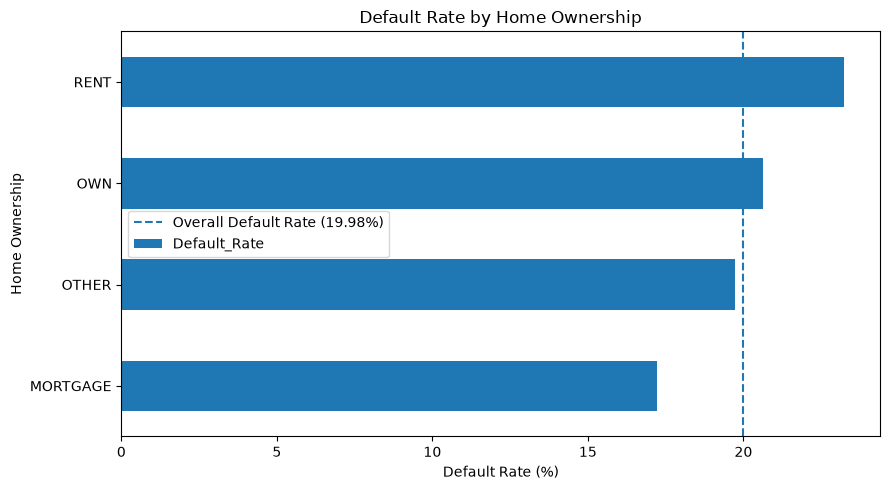

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

home_analysis['Default_Rate'].sort_values().plot(
    kind='barh'
)

plt.axvline(
    x=default_rate,
    linestyle='--',
    label=f'Overall Default Rate ({default_rate:.2f}%)'
)

plt.title('Default Rate by Home Ownership')
plt.xlabel('Default Rate (%)')
plt.ylabel('Home Ownership')
plt.legend()
plt.tight_layout()
plt.show()

Step 9 – Default rate by FICO score group

In [9]:
# Create FICO score groups

df['FICO_Group'] = pd.cut(
    df['fico_n'],
    bins=[0, 640, 680, 720, 760, 851],
    labels=[
        'Below 640',
        '640–680',
        '680–720',
        '720–760',
        '760–850'
    ],
    right=False
)

fico_analysis = df.groupby(
    'FICO_Group', observed=False
).agg(
    Total_Borrowers=('Default', 'count'),
    Default_Count=('Default', 'sum'),
    Average_Loan_Amount=('loan_amnt', 'mean'),
    Average_DTI=('dti_capped', 'mean')
)

fico_analysis['Default_Rate'] = (
    fico_analysis['Default_Count'] /
    fico_analysis['Total_Borrowers'] * 100
)

fico_analysis = fico_analysis.round(2)

print("DEFAULT DISTRIBUTION BY FICO SCORE")
print(fico_analysis)

DEFAULT DISTRIBUTION BY FICO SCORE
            Total_Borrowers  Default_Count  Average_Loan_Amount  Average_DTI  \
FICO_Group                                                                     
Below 640                17              8              2916.18         7.18   
640–680              460588         116537             12993.21        18.24   
680–720              608501         120272             14939.25        18.78   
720–760              201591          26027             15789.42        17.75   
760–850               76984           6405             15062.62        14.76   

            Default_Rate  
FICO_Group                
Below 640          47.06  
640–680            25.30  
680–720            19.77  
720–760            12.91  
760–850             8.32  


Interpretation – Default distribution by FICO score
Your results show a strong inverse relationship between FICO score and default rate.
FICO group	Borrowers	Default rate
Below 640	17	47.06%
640–680	460,588	25.30%
680–720	608,501	19.77%
720–760	201,591	12.91%
760–850	76,984	8.32%

Key business observations
1. Below 640: Highest default rate (47.06%), but only 17 borrowers. This result is not representative of a large segment.
2. 640–680: Default rate is 25.30%, considerably above the portfolio average of 19.98%.
3. 680–720: Default rate is 19.77%, close to the portfolio average.
4. 720–760: Default rate decreases to 12.91%.
5. 760–850: Lowest default rate at 8.32%.
Business implication: FICO score is an important indicator for borrower risk segmentation. Higher FICO categories in this dataset are associated with lower observed default rates.

Step 10 – Visualize default rates by FICO group

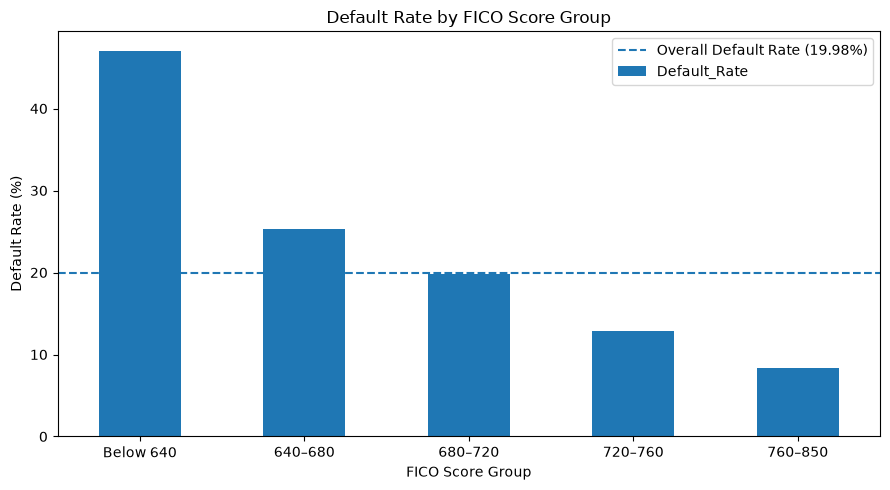

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

fico_analysis['Default_Rate'].plot(
    kind='bar',
    rot=0
)

plt.axhline(
    y=default_rate,
    linestyle='--',
    label=f'Overall Default Rate ({default_rate:.2f}%)'
)

plt.title('Default Rate by FICO Score Group')
plt.xlabel('FICO Score Group')
plt.ylabel('Default Rate (%)')
plt.legend()
plt.tight_layout()
plt.show()

Step 11 – Default distribution by DTI group
Next, investigate how borrowers' Debt-to-Income (DTI) ratios relate to default risk.

# Create DTI groups

df['DTI_Group'] = pd.cut(
    df['dti_capped'],
    bins=[-float('inf'), 10, 20, 30, 40, float('inf')],  # right-closed: (a, b]
    labels=[
        '≤10',
        '10–20',
        '20–30',
        '30–40',
        '>40'
    ]
)

dti_analysis = df.groupby(
    'DTI_Group', observed=False
).agg(
    Total_Borrowers=('Default', 'count'),
    Default_Count=('Default', 'sum'),
    Average_Loan_Amount=('loan_amnt', 'mean'),
    Average_FICO=('fico_n', 'mean')
)

dti_analysis['Default_Rate'] = (
    dti_analysis['Default_Count'] /
    dti_analysis['Total_Borrowers'] * 100
)

dti_analysis = dti_analysis.round(2)

print("DEFAULT DISTRIBUTION BY DTI GROUP")
print(dti_analysis)

Interpretation – Default distribution by DTI group
Your results show a clear positive relationship between DTI and default rate.
DTI group	Borrowers	Default rate
≤10	245,652	14.84%
10–20	563,434	17.85%
20–30	409,868	23.08%
30–40	121,923	29.13%
>40	6,804	30.67%

Key business observations
1. ≤10: Lowest default rate at 14.84%.
2. 10–20: Default rate increases to 17.85%.
3. 20–30: Default rate rises to 23.08%, above the portfolio average.
4. 30–40: Default rate reaches 29.13%.
5. >40: Highest default rate at 30.67%, although this group has relatively few borrowers.
Business implication: Borrowers with higher DTI ratios demonstrate higher observed default rates. DTI can therefore be an important indicator when assessing repayment capacity.

Step 12 – Visualize default rates by DTI group

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

dti_analysis['Default_Rate'].plot(
    kind='bar',
    rot=0
)

plt.axhline(
    y=default_rate,
    linestyle='--',
    label=f'Overall Default Rate ({default_rate:.2f}%)'
)

plt.title('Default Rate by DTI Group')
plt.xlabel('DTI Group')
plt.ylabel('Default Rate (%)')
plt.legend()
plt.tight_layout()
plt.show()

Next: Step 13 – Default distribution by State (addr_state).

We will compare borrower counts and default rates across states to identify geographic variations in credit risk.

In [13]:
state_analysis = df.groupby('addr_state').agg(
    Total_Borrowers=('Default', 'count'),
    Default_Count=('Default', 'sum')
)

state_analysis['Default_Rate'] = (
    state_analysis['Default_Count'] /
    state_analysis['Total_Borrowers'] * 100
)

state_analysis = state_analysis.sort_values(
    'Default_Rate', ascending=False
).round(2)

print("DEFAULT DISTRIBUTION BY STATE")
print(state_analysis)

DEFAULT DISTRIBUTION BY STATE
            Total_Borrowers  Default_Count  Default_Rate
addr_state                                              
MS                     6593           1722         26.12
NE                     3591            905         25.20
AR                    10058           2425         24.11
AL                    16640           3933         23.64
OK                    12291           2884         23.46
LA                    15520           3596         23.17
NY                   110075          24267         22.05
NV                    20282           4457         21.98
FL                    95815          20599         21.50
IN                    21720           4656         21.44
IA                       14              3         21.43
TN                    20393           4368         21.42
NM                     7374           1576         21.37
MO                    21328           4551         21.34
SD                     2770            591         21.34
M

Interpretation – Default distribution by State
Your results show noticeable geographic variation in default rates.

1. States with the highest default rates
State	Borrowers	Default rate
MS	6,593	26.12%
NE	3,591	25.20%
AR	10,058	24.11%
AL	16,640	23.64%
OK	12,291	23.46%

2. States with the lowest default rates
State	Borrowers	Default rate
DC	3,485	13.23%
ME	2,029	13.85%
VT	2,655	13.97%
OR	16,415	14.41%
NH	6,463	14.58%

3. Important business observations
- Mississippi has the highest observed default rate (26.12%).
- Washington DC has the lowest (13.23%).
- New York and Texas have large borrower populations and substantial default counts.
- California has the largest borrower population (196,805), with a default rate of 19.63%.
- Iowa has only 14 borrowers, so its default rate is not statistically reliable for comparison.
Business implication: Geographic differences may help lenders identify areas requiring closer portfolio monitoring. However, state-level default rates alone do not establish why borrowers default.

Step 14 – Visualize default rates by State

import matplotlib.pyplot as plt

# Exclude states with very few borrowers (e.g. Iowa, 14 borrowers) - rates are unreliable
reliable_states = state_analysis[state_analysis['Total_Borrowers'] >= 1000]
top_states = reliable_states.nlargest(15, 'Default_Rate')

plt.figure(figsize=(11, 6))

plt.barh(
    top_states.index,
    top_states['Default_Rate']
)

plt.axvline(
    x=default_rate,
    linestyle='--',
    label=f'Overall Default Rate ({default_rate:.2f}%)'
)

plt.title('Top 15 States by Default Rate (states with ≥1,000 borrowers)')
plt.xlabel('Default Rate (%)')
plt.ylabel('State')
plt.gca().invert_yaxis()
plt.legend()
plt.tight_layout()
plt.show()

Next: Step 15 – Cluster-wise Business Analysis

In [15]:
print("K-Means cluster column available:",
      'KMeans_Cluster' in df.columns)

print("\nCurrent dataset columns:")
print(df.columns.tolist())

K-Means cluster column available: False

Current dataset columns:
['id', 'issue_d', 'revenue', 'dti_n', 'loan_amnt', 'fico_n', 'experience_c', 'emp_length', 'purpose', 'home_ownership_n', 'addr_state', 'Default', 'revenue_log', 'dti_capped', 'dti_extreme', 'loan_amnt_log', 'FICO_Group', 'DTI_Group']


Step 16 – Check clustering feature availability

In [16]:
clustering_features = [
    'revenue_log',
    'loan_amnt_log',
    'fico_n',
    'dti_capped',
    'emp_length',
    'purpose',
    'home_ownership_n'
]

print("Available clustering features:")
print([col for col in clustering_features if col in df.columns])

print("\nMissing clustering features:")
print([col for col in clustering_features if col not in df.columns])

Available clustering features:
['revenue_log', 'loan_amnt_log', 'fico_n', 'dti_capped', 'emp_length', 'purpose', 'home_ownership_n']

Missing clustering features:
[]


Step 17 – Preprocess clustering features

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from scipy.sparse import csr_matrix

numeric_features = [
    'revenue_log',
    'loan_amnt_log',
    'fico_n',
    'dti_capped'
]

categorical_features = [
    'emp_length',
    'purpose',
    'home_ownership_n'
]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

X_cluster = preprocessor.fit_transform(df)

print("Original dataset shape:", df.shape)
print("Transformed feature matrix shape:", X_cluster.shape)
print("Matrix type:", type(X_cluster))

Original dataset shape: (1347681, 18)
Transformed feature matrix shape: (1347681, 34)
Matrix type: <class 'scipy.sparse._csr.csr_matrix'>


Step 18 – Apply K-Means clustering (K = 4)

In [18]:
from sklearn.cluster import MiniBatchKMeans

kmeans = MiniBatchKMeans(
    n_clusters=4,
    random_state=42,
    batch_size=10000,
    n_init=3
)

df['KMeans_Cluster'] = kmeans.fit_predict(X_cluster)

print("K-Means clustering completed.")

print("\nCluster Distribution:")
print(df['KMeans_Cluster'].value_counts().sort_index())

print("\nCluster Percentages:")
print(
    (df['KMeans_Cluster'].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

K-Means clustering completed.

Cluster Distribution:
KMeans_Cluster
0    167418
1    515723
2    444501
3    220039
Name: count, dtype: int64

Cluster Percentages:
KMeans_Cluster
0    12.42
1    38.27
2    32.98
3    16.33
Name: proportion, dtype: float64


Step 19 – Financial and credit profile by cluster

In [19]:
cluster_analysis = df.groupby('KMeans_Cluster').agg(
    Total_Borrowers=('Default', 'count'),
    Default_Count=('Default', 'sum'),
    Average_Loan_Amount=('loan_amnt', 'mean'),
    Average_Revenue=('revenue', 'mean'),
    Average_FICO=('fico_n', 'mean'),
    Average_DTI=('dti_capped', 'mean')
)

cluster_analysis['Default_Rate'] = (
    cluster_analysis['Default_Count'] /
    cluster_analysis['Total_Borrowers'] * 100
)

cluster_analysis = cluster_analysis.round(2)

print("FINANCIAL AND CREDIT PROFILE BY K-MEANS CLUSTER")
print(cluster_analysis)

FINANCIAL AND CREDIT PROFILE BY K-MEANS CLUSTER
                Total_Borrowers  Default_Count  Average_Loan_Amount  \
KMeans_Cluster                                                        
0                        167418          17487              8368.75   
1                        515723         116614             17612.26   
2                        444501         104080              8255.10   
3                        220039          31068             23923.81   

                Average_Revenue  Average_FICO  Average_DTI  Default_Rate  
KMeans_Cluster                                                            
0                      58973.67        742.81        13.34         10.45  
1                      88321.89        681.87        16.57         22.61  
2                      45423.13        683.90        22.10         23.42  
3                     130232.10        731.18        17.90         14.12  


Interpretation – Financial and Credit Profile by K-Means Cluster
Your K-Means model has identified four distinct borrower segments with different financial profiles and default risks.
1. Cluster comparison
Metric	Cluster 0	Cluster 1	Cluster 2	Cluster 3
Borrowers	167,418	515,723	444,501	220,039
Default rate	10.45%	22.61%	23.42%	14.12%
Avg. loan	$8,369	$17,612	$8,255	$23,924
Avg. revenue	$58,974	$88,322	$45,423	$130,232
Avg. FICO	742.81	681.87	683.90	731.18
Avg. DTI	13.34	16.57	22.10	17.90

2. Business interpretation of each cluster
Cluster 0 – Low-risk borrowers
- Highest average FICO score (742.81).
- Lowest average DTI (13.34).
- Lowest default rate (10.45%).
- Relatively small average loan amount ($8,369).
Business insight: This segment demonstrates comparatively strong credit profiles and lower observed default risk.

Cluster 1 – Moderate-to-high-risk borrowers
- Largest segment, representing 38.27% of borrowers.
- Average FICO is relatively low (681.87).
- Default rate is 22.61%.
- Average loan amount is $17,612.
Business insight: Because this is the largest segment, its default behaviour has substantial importance for overall portfolio performance.

Cluster 2 – High-risk borrowers
- Second-largest segment, representing 32.98%.
- Highest default rate (23.42%).
- Lowest average revenue ($45,423).
- Highest average DTI (22.10).
- Relatively low average FICO (683.90).
Business insight: This segment combines lower income, higher debt burden and weaker credit scores, making it an important segment for closer credit-risk monitoring.

Cluster 3 – High-income, relatively low-risk borrowers
- Highest average revenue ($130,232).
- Highest average loan amount ($23,924).
- Second-highest FICO (731.18).
- Default rate is relatively low at 14.12%.
Business insight: Despite larger loan amounts, this segment demonstrates comparatively strong credit quality.
3. Overall business conclusion
- Cluster 2 has the highest default rate (23.42%).
- Cluster 1 contributes the largest number of defaults (116,614).
- Cluster 0 has the lowest default rate (10.45%).
- Cluster 3 combines the highest average revenue with a relatively low default rate.
Important: These are descriptive segments, not proof that any individual borrower will default. The clusters were formed without using the Default target.

Step 20 – Visualize default rates across clusters

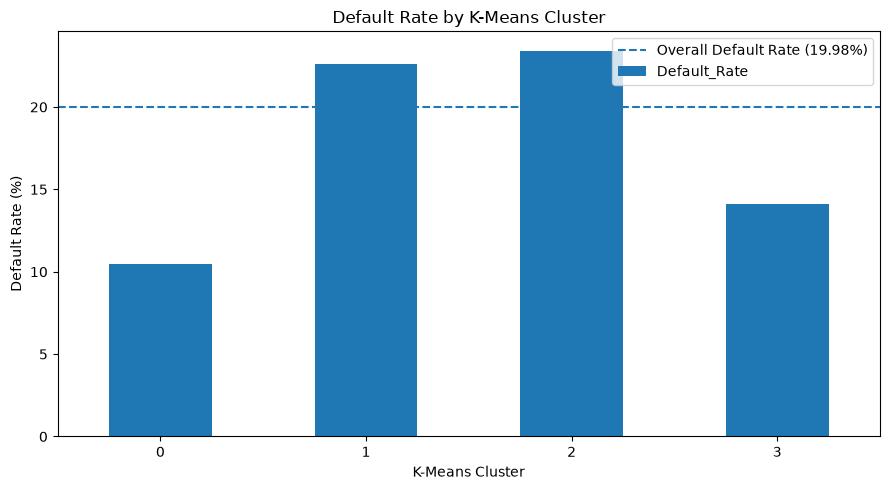

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

cluster_analysis['Default_Rate'].plot(
    kind='bar',
    rot=0
)

plt.axhline(
    y=default_rate,
    linestyle='--',
    label=f'Overall Default Rate ({default_rate:.2f}%)'
)

plt.title('Default Rate by K-Means Cluster')
plt.xlabel('K-Means Cluster')
plt.ylabel('Default Rate (%)')
plt.legend()
plt.tight_layout()
plt.show()

Step 21 – Visualize borrower distribution across clusters

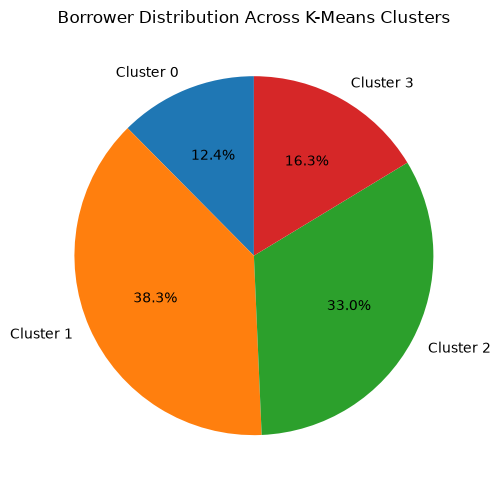

In [21]:
import matplotlib.pyplot as plt

cluster_distribution = df['KMeans_Cluster'].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.pie(
    cluster_distribution,
    labels=[
        f'Cluster {i}' for i in cluster_distribution.index
    ],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Borrower Distribution Across K-Means Clusters')
plt.tight_layout()
plt.show()

Step 22 – Compare financial characteristics across clusters

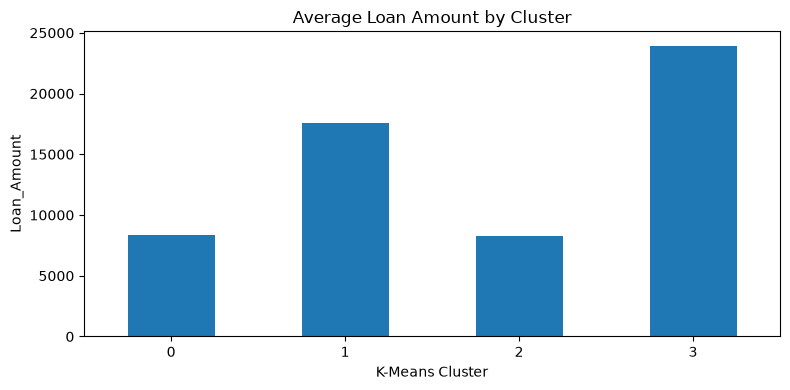

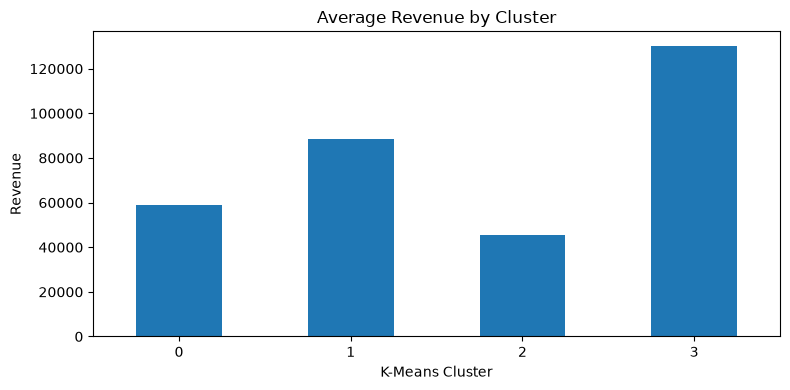

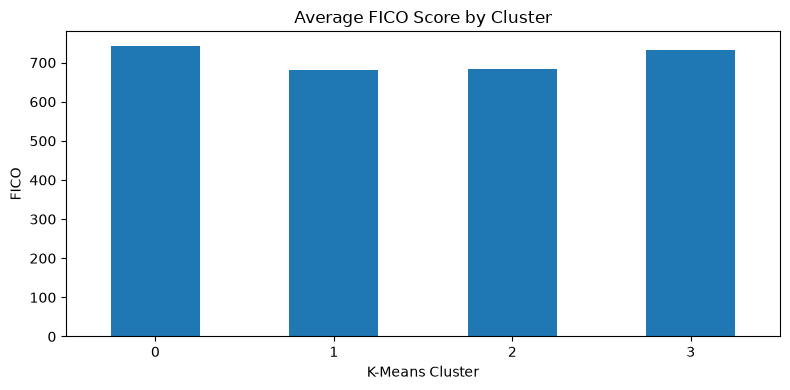

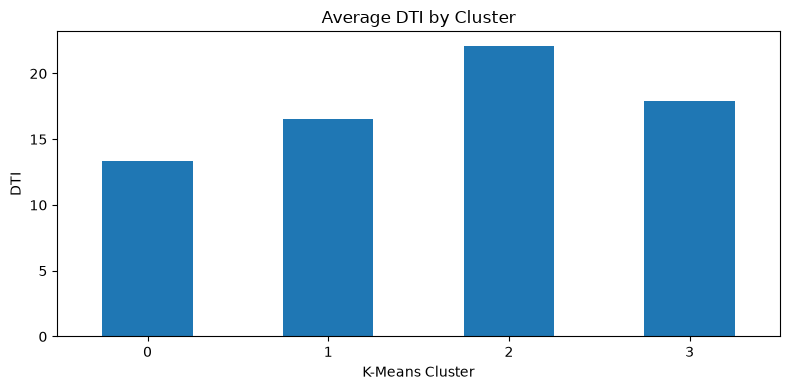

In [22]:
import matplotlib.pyplot as plt

metrics = [
    'Average_Loan_Amount',
    'Average_Revenue',
    'Average_FICO',
    'Average_DTI'
]

titles = [
    'Average Loan Amount by Cluster',
    'Average Revenue by Cluster',
    'Average FICO Score by Cluster',
    'Average DTI by Cluster'
]

for metric, title in zip(metrics, titles):

    plt.figure(figsize=(8, 4))

    cluster_analysis[metric].plot(
        kind='bar',
        rot=0
    )

    plt.title(title)
    plt.xlabel('K-Means Cluster')
    plt.ylabel(metric.replace('Average_', ''))
    plt.tight_layout()
    plt.show()

Step 23 – Prepare Actionable Business Recommendations

Based on your actual EDA and K-Means results, the following recommendations can be included in your project report.
1. Improve credit-risk assessment
- Give greater attention to borrowers with lower FICO scores.
- The 640–680 FICO group has a 25.30% default rate, compared with 8.32% for the 760–850 group.
- Use FICO scores alongside income, DTI and repayment history when evaluating applications.
2. Introduce DTI-based risk monitoring
- Borrowers with DTI above 30 (30–40 and >40 groups) have default rates exceeding 29%.
- The >40 DTI group has a 30.67% default rate.
- Apply additional affordability checks to borrowers with high DTI ratios.
3. Strengthen employment and income verification
- Borrowers with employment length recorded as NI have a 26.96% default rate.
- Verify employment and income information carefully.
- Consider employment stability as one factor in credit assessment, rather than an independent rejection criterion.
4. Monitor loan-purpose risk
- Small-business loans have the highest observed purpose-based default rate at 29.86%.
- Debt consolidation represents the largest borrower segment, with 21.15% defaults.
- Apply suitable risk assessment policies for different loan purposes.
5. Monitor geographic credit risk
- Mississippi has the highest observed state default rate at 26.12%.
- California has the largest borrower population, with 196,805 borrowers.
- Monitor state-level portfolio performance regularly, while accounting for differences in borrower counts.
6. Implement cluster-based lending strategies
Cluster	Default rate	Recommended strategy
0	10.45%	Consider standard lending policies for this comparatively lower-risk segment
1	22.61%	Strengthen affordability and credit checks
2	23.42%	Apply closer risk assessment and repayment-capacity checks
3	14.12%	Consider suitable lending opportunities with appropriate verification

7. Improve portfolio monitoring
- Track default rates by borrower segment.
- Monitor changes in FICO and DTI distributions.
- Identify increasing default trends early.
- Review lending policies using historical portfolio performance.

Final project conclusion
Business Insights and Recommendations – Conclusion
The business analysis of 1,347,681 loan records revealed important patterns in borrower characteristics and loan default behaviour. The overall portfolio default rate was 19.98%.

The analysis identified higher default rates among borrowers with lower FICO scores, higher debt-to-income ratios, shorter or unreported employment histories, and certain loan purposes and geographic locations.

K-Means clustering identified four distinct borrower segments. Cluster 2 recorded the highest default rate of 23.42%, while Cluster 0 recorded the lowest rate of 10.45%. These segments provide useful insights for understanding differences in borrower financial profiles and credit risk.

The findings suggest that lending institutions can improve portfolio management through better borrower segmentation, affordability assessment, FICO and DTI monitoring, employment verification, and continuous portfolio risk monitoring.

Overall, the analysis demonstrates how exploratory data analysis, visualization and machine learning clustering can support data-driven lending decisions and more effective credit-risk management.